# Coronary Artery Disease Survival Prediction

## Imports & Dataset Overview (Shape, Sample & Memory)


In [41]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid")
DEFAULT_FIGSIZE = (12, 5)
plt.rcParams["figure.figsize"] = DEFAULT_FIGSIZE

data_path = Path("../data/patients_med_data.csv")
if not data_path.exists():
    data_path = Path("../data/patients_med_data.xlsx")

df = pd.read_csv(data_path) if data_path.suffix.lower() == ".csv" else pd.read_excel(data_path)
df.columns = [c.strip() for c in df.columns]

mem_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"Loaded file: {data_path.name} | Shape: {df.shape} | Memory Usage: {mem_mb:.2f} MB")
display(df.head(5))
display(df.sample(5, random_state=42))
display(df.info())


Loaded file: patients_med_data.csv | Shape: (15000, 16) | Memory Usage: 7.16 MB


,ID,Survive,Gender,Smoke,Diabetes,Age,Ejection Fraction,Sodium,Creatinine,Platelets,Creatine phosphokinase,Blood Pressure,Hemoglobin,Height,Weight,Favorite color
0,TIG1GE,0,Male,Yes,Normal,50,Low,141,0.7,266000.0,185,105,12.3,180,93,green
1,VXUCV9,1,Male,No,Normal,75,Low,134,2.5,224000.0,99,162,13.0,140,47,black
2,AFH4F1,1,Female,No,Pre-diabetes,80,Low,135,1.3,192000.0,776,179,12.4,150,61,white
3,ZK6PAC,0,Male,No,Normal,-60,Low,136,0.9,228000.0,2261,136,15.3,130,48,yellow
4,6CVBRT,0,Female,No,Normal,70,Low,141,0.9,358000.0,1202,171,13.3,177,64,blue


,ID,Survive,Gender,Smoke,Diabetes,Age,Ejection Fraction,Sodium,Creatinine,Platelets,Creatine phosphokinase,Blood Pressure,Hemoglobin,Height,Weight,Favorite color
11499,U7SJRX,0,Female,No,Diabetes,60,Low,137,1.2,318000.0,156,170,10.3,148,69,blue
6475,TBBFXR,0,Male,No,Diabetes,50,L,136,1.6,252000.0,369,77,13.2,133,55,green
13167,ETT7FW,1,Male,No,Pre-diabetes,69,Low,134,3.5,228000.0,582,40,13.1,178,117,white
862,CCIYUR,0,Male,No,Diabetes,60,Low,137,2.3,305000.0,2656,107,15.8,171,108,black
5970,9OWBEE,1,Female,No,Normal,54,Normal,137,9.0,151000.0,427,131,10.9,135,37,blue


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID                      15000 non-null  object 
 1   Survive                 15000 non-null  object 
 2   Gender                  15000 non-null  object 
 3   Smoke                   15000 non-null  object 
 4   Diabetes                15000 non-null  object 
 5   Age                     15000 non-null  int64  
 6   Ejection Fraction       15000 non-null  object 
 7   Sodium                  15000 non-null  int64  
 8   Creatinine              14501 non-null  float64
 9   Platelets               15000 non-null  float64
 10  Creatine phosphokinase  15000 non-null  int64  
 11  Blood Pressure          15000 non-null  int64  
 12  Hemoglobin              15000 non-null  float64
 13  Height                  15000 non-null  int64  
 14  Weight                  15000 non-null

None

## Duplicate, Missing Value & Typo Audit

In [42]:
print("=== 1. Duplicate Check ===")
print(f"Exact duplicate rows: {df.duplicated().sum()}")
if "ID" in df.columns:
    print(f"Duplicate Patient IDs: {df['ID'].duplicated().sum()}")

print("\n=== 2. Missing Values per Column ===")
missing_summary = df.isnull().sum()
display(missing_summary[missing_summary > 0] if missing_summary.sum() > 0 else "No explicit NaN values found.")

print("\n=== 3. Unique Values in Categorical / Target Columns ===")
for col in ["Survive", "Gender", "Smoke", "Diabetes", "Ejection Fraction", "Favourite color"]:
    if col in df.columns:
        print(f"{col}: {df[col].unique().tolist()}")


=== 1. Duplicate Check ===
Exact duplicate rows: 0
Duplicate Patient IDs: 958

=== 2. Missing Values per Column ===


Creatinine    499
dtype: int64


=== 3. Unique Values in Categorical / Target Columns ===
Survive: ['0', '1', 'No', 'Yes']
Gender: ['Male', 'Female']
Smoke: ['Yes', 'No', 'NO', 'YES']
Diabetes: ['Normal', 'Pre-diabetes', 'Diabetes']
Ejection Fraction: ['Low', 'Normal', 'High', 'L', 'N']


### Interpredation

* **Missing Data Strategy (Creatinine: 499 Missing Values):** We retain all 499 rows (~3.5% of cleaned records) and impute missing Creatinine values with the **training-fold median** rather than dropping rows. Deleting rows discards 13 valid clinical features per patient, introduces selection bias toward over-tested patients, and breaks production inference when a new patient has a pending lab result.

## Vectorized Cleaning, Typo Standardization & Cleaning Impact Audit

In [43]:
initial_rows = len(df)
df_clean = df.copy()

# 1. Deduplicate patient records
if "ID" in df_clean.columns:
    df_clean = df_clean.drop_duplicates(subset=["ID"], keep="first")
after_dedup_rows = len(df_clean)

# 2. Strip whitespace across object/string columns
for col in df_clean.select_dtypes(include=["object", "string"]).columns:
    df_clean[col] = df_clean[col].astype(str).str.strip()

# 3. Standardize Target ('Survive') using .map() (zero FutureWarning)
survive_map = {
    "1": 1, "yes": 1, "y": 1, "survived": 1, "true": 1, "alive": 1,
    "0": 0, "no": 0, "n": 0, "died": 0, "false": 0, "deceased": 0
}
df_clean["Survive"] = (
    df_clean["Survive"].astype(str).str.strip().str.lower()
    .map(lambda x: survive_map.get(x, x))
)
df_clean["Survive"] = pd.to_numeric(df_clean["Survive"], errors="coerce")
df_clean = df_clean.dropna(subset=["Survive"])
df_clean["Survive"] = df_clean["Survive"].astype(int)
final_rows = len(df_clean)

# 4. Standardize categorical typos
gender_map = {"m": "Male", "male": "Male", "f": "Female", "female": "Female"}
smoke_map = {"y": "Yes", "yes": "Yes", "1": "Yes", "n": "No", "no": "No", "0": "No"}
diabetes_map = {
    "normal": "Normal", "no": "Normal", "n": "Normal", "0": "Normal",
    "pre-diabetes": "Pre-diabetes", "prediabetes": "Pre-diabetes", "pre diabetes": "Pre-diabetes",
    "diabetes": "Diabetes", "yes": "Diabetes", "y": "Diabetes", "1": "Diabetes"
}
ef_map = {"low": "Low", "l": "Low", "normal": "Normal", "norm": "Normal", "n": "Normal", "high": "High", "h": "High"}

df_clean["Gender"] = df_clean["Gender"].str.lower().map(lambda x: gender_map.get(x, x))
df_clean["Smoke"] = df_clean["Smoke"].str.lower().map(lambda x: smoke_map.get(x, x))
df_clean["Diabetes"] = df_clean["Diabetes"].str.lower().map(lambda x: diabetes_map.get(x, x))
df_clean["Ejection Fraction"] = df_clean["Ejection Fraction"].str.lower().map(lambda x: ef_map.get(x, x))

# 5. Fix Negative Age & Impossible Zeros
df_clean["Age"] = pd.to_numeric(df_clean["Age"], errors="coerce").abs()
df_clean.loc[(df_clean["Age"] < 1) | (df_clean["Age"] > 120), "Age"] = np.nan

numeric_cols = [
    "Sodium", "Creatinine", "Platelets", "Creatine phosphokinase",
    "Blood Pressure", "Hemoglobin", "Height", "Weight"
]
for col in numeric_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")
    df_clean.loc[df_clean[col] <= 0, col] = np.nan

# 6. Feature Engineering: BMI & Clinical Interaction (Age * Creatinine)
df_clean["BMI"] = df_clean["Weight"] / ((df_clean["Height"] / 100.0) ** 2)
df_clean["Age_x_Creatinine"] = df_clean["Age"] * df_clean["Creatinine"]

# 7. Drop noise columns
df_clean = df_clean.drop(columns=[c for c in ["ID", "Favourite color"] if c in df_clean.columns])

print("=== Cleaning Impact Summary ===")
print(f"Initial Raw Rows          : {initial_rows}")
print(f"After ID Deduplication    : {after_dedup_rows} (Removed {initial_rows - after_dedup_rows} duplicates)")
print(f"After Target Validation   : {final_rows} (Removed {after_dedup_rows - final_rows} unmappable targets)")
display(df_clean.describe().T)


=== Cleaning Impact Summary ===
Initial Raw Rows          : 15000
After ID Deduplication    : 14042 (Removed 958 duplicates)
After Target Validation   : 14042 (Removed 0 unmappable targets)


,count,mean,std,min,25%,50%,75%,max
Survive,14042.0,0.321393,0.467028,0.000000,0.000000,0.000000,1.000000,1.000000
Age,14042.0,60.890614,11.882182,40.000000,51.000000,60.000000,70.000000,95.000000
Sodium,14042.0,136.585387,4.371699,113.000000,134.000000,137.000000,140.000000,148.000000
Creatinine,13576.0,1.412341,1.043844,0.500000,0.900000,1.100000,1.400000,9.400000
Platelets,14042.0,262854.587738,97795.069773,25100.000000,211000.000000,262000.000000,304000.000000,850000.000000
Creatine phosphokinase,14042.0,578.983834,947.591804,23.000000,118.000000,250.000000,582.000000,7861.000000
Blood Pressure,14042.0,103.649480,39.699495,40.000000,70.000000,100.000000,137.000000,179.000000
Hemoglobin,14042.0,12.920937,2.500790,9.000000,10.700000,12.700000,15.100000,17.500000
Height,14042.0,159.427076,17.323065,130.000000,144.000000,160.000000,174.000000,189.000000
Weight,14042.0,69.283008,25.253227,19.000000,50.000000,66.000000,87.000000,141.000000


## Binary & Ordinal Encoding

In [44]:
df_encoded = df_clean.copy()

# Diagnostic: check if any categorical column has unexpected text values
for col in ["Gender", "Smoke", "Diabetes", "Ejection Fraction"]:
    print(f"Unique values in {col}: {df_encoded[col].unique().tolist()}")

# 1. Binary Encoding
df_encoded["Gender_Encoded"] = df_encoded["Gender"].map({"Female": 0, "Male": 1})
df_encoded["Smoke_Encoded"] = df_encoded["Smoke"].map({"No": 0, "Yes": 1})

# 2. Ordinal Encoding
df_encoded["Ejection_Fraction_Encoded"] = df_encoded["Ejection Fraction"].map({"Low": 0, "Normal": 1, "High": 2})
df_encoded["Diabetes_Encoded"] = df_encoded["Diabetes"].map({"Normal": 0, "Pre-diabetes": 1, "Diabetes": 2})

df_encoded = df_encoded.drop(columns=["Gender", "Smoke", "Diabetes", "Ejection Fraction"])

# Drop any column that is 100% NaN (if an unexpected category label existed) and fill remaining NaNs with median for VIF/RF
df_encoded = df_encoded.dropna(axis=1, how="all")
print("\nRemaining NaNs per column in df_encoded:")
print(df_encoded.isnull().sum()[df_encoded.isnull().sum() > 0])
display(df_encoded.head())


Unique values in Gender: ['Male', 'Female']
Unique values in Smoke: ['Yes', 'No']
Unique values in Diabetes: ['Normal', 'Pre-diabetes', 'Diabetes']
Unique values in Ejection Fraction: ['Low', 'Normal', 'High']

Remaining NaNs per column in df_encoded:
Creatinine          466
Age_x_Creatinine    466
dtype: int64


,Survive,Age,Sodium,Creatinine,Platelets,Creatine phosphokinase,Blood Pressure,Hemoglobin,Height,Weight,Favorite color,BMI,Age_x_Creatinine,Gender_Encoded,Smoke_Encoded,Ejection_Fraction_Encoded,Diabetes_Encoded
0,0,50.0,141.0,0.7,266000.0,185.0,105.0,12.3,180.0,93.0,green,28.703704,35.0,1,1,0,0
1,1,75.0,134.0,2.5,224000.0,99.0,162.0,13.0,140.0,47.0,black,23.979592,187.5,1,0,0,0
2,1,80.0,135.0,1.3,192000.0,776.0,179.0,12.4,150.0,61.0,white,27.111111,104.0,0,0,0,1
3,0,60.0,136.0,0.9,228000.0,2261.0,136.0,15.3,130.0,48.0,yellow,28.402367,54.0,1,0,0,0
4,0,70.0,141.0,0.9,358000.0,1202.0,171.0,13.3,177.0,64.0,blue,20.428357,63.0,0,0,0,0


## Target Balance & Explicit Imbalance Ratio

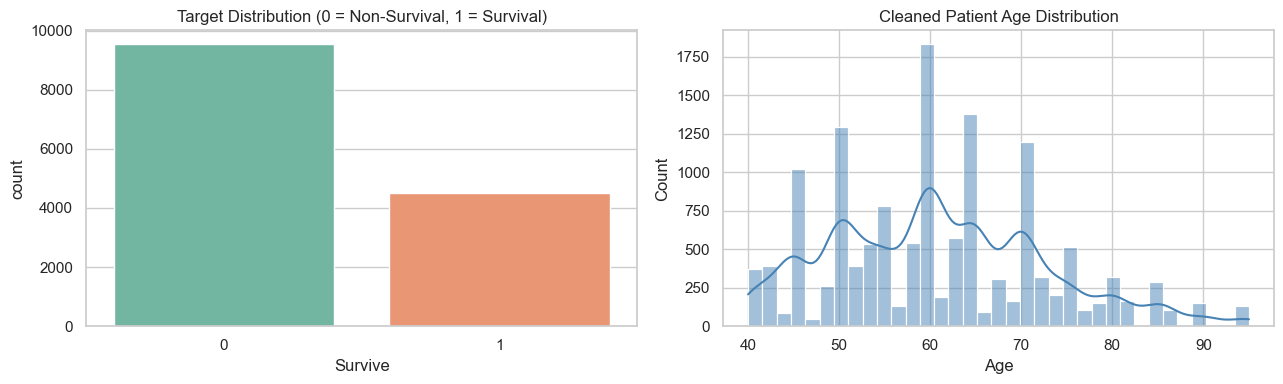

Class Counts:
Survive
0    9529
1    4513
Name: count, dtype: int64

Class Proportions (%):
Survive
0    67.86
1    32.14
Name: proportion, dtype: float64

Majority-to-Minority Imbalance Ratio: 2.11 : 1


In [45]:
counts = df_clean["Survive"].value_counts()
props = (df_clean["Survive"].value_counts(normalize=True) * 100).round(2)
imbalance_ratio = counts.max() / counts.min()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df_clean, x="Survive", hue="Survive", ax=ax1, palette="Set2", legend=False)
ax1.set_title("Target Distribution (0 = Non-Survival, 1 = Survival)")

sns.histplot(data=df_clean, x="Age", kde=True, bins="auto", ax=ax2, color="steelblue")
ax2.set_title("Cleaned Patient Age Distribution")
plt.tight_layout()
plt.show()

print(f"Class Counts:\n{counts}\n")
print(f"Class Proportions (%):\n{props}\n")
print(f"Majority-to-Minority Imbalance Ratio: {imbalance_ratio:.2f} : 1")


## Dedicated Outlier Analysis (IQR Threshold Table & Univariate Boxplot Grid)

,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Pct (%)
2,Creatinine,0.90,1.40,0.5,0.15,2.15,1429,10.53
4,Creatine phosphokinase,118.00,582.00,464.0,-578.00,1278.00,1388,9.88
3,Platelets,211000.00,304000.00,93000.0,71500.00,443500.00,880,6.27
1,Sodium,134.00,140.00,6.0,125.00,149.00,175,1.25
0,Age,51.00,70.00,19.0,22.50,98.50,0,0.00
5,Blood Pressure,70.00,137.00,67.0,-30.50,237.50,0,0.00
6,Hemoglobin,10.70,15.10,4.4,4.10,21.70,0,0.00
7,BMI,19.72,32.72,13.0,0.22,52.22,0,0.00


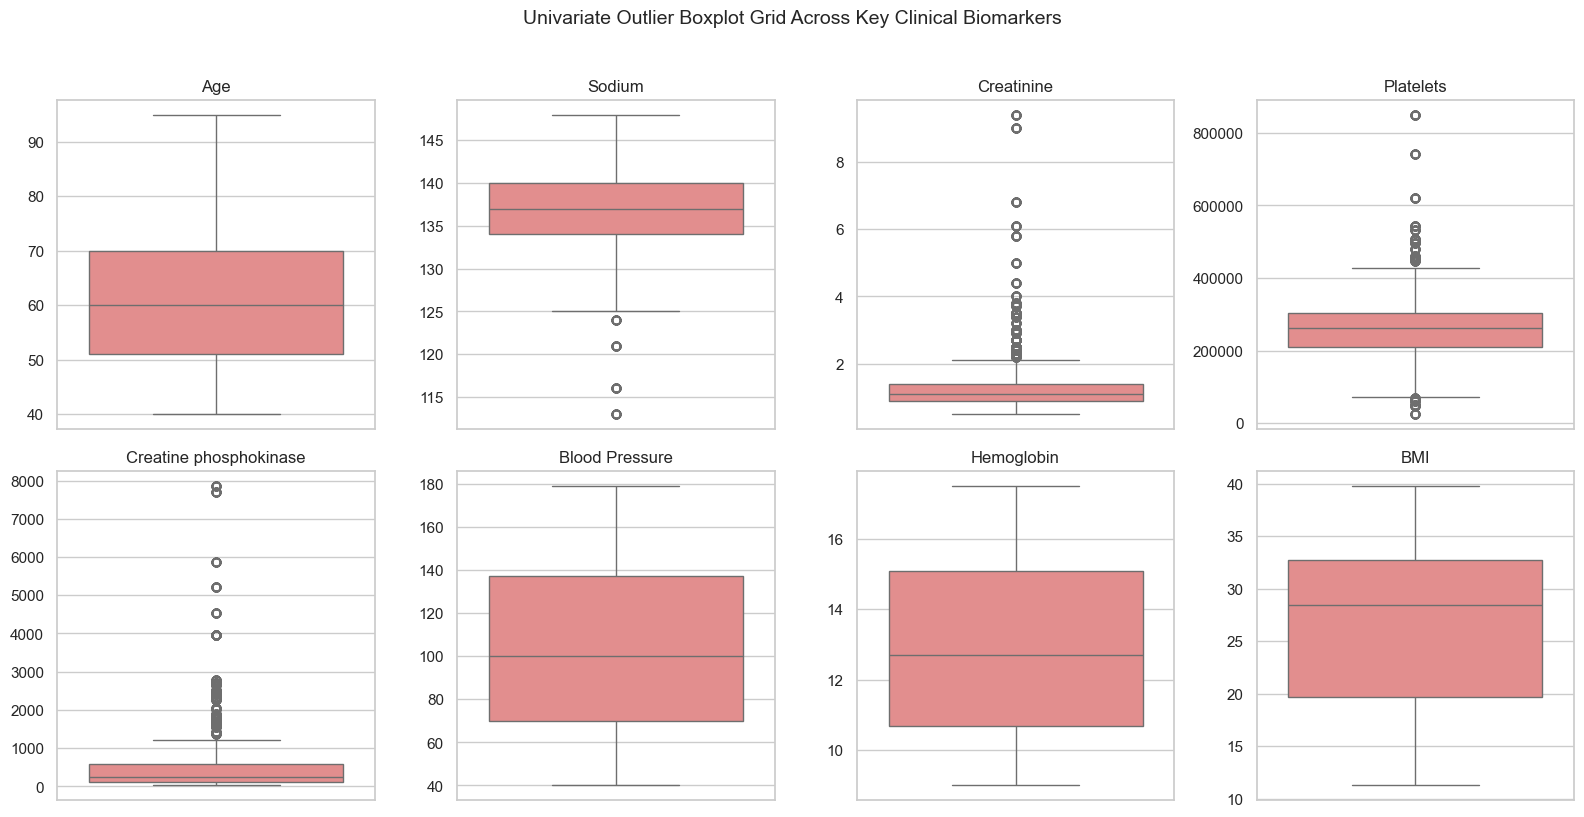

In [46]:
outlier_features = [
    "Age", "Sodium", "Creatinine", "Platelets",
    "Creatine phosphokinase", "Blood Pressure", "Hemoglobin", "BMI"
]

outlier_records = []
for col in outlier_features:
    series = df_clean[col].dropna()
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = int(((series < lower) | (series > upper)).sum())
    outlier_records.append({
        "Feature": col,
        "Q1": round(q1, 2),
        "Q3": round(q3, 2),
        "IQR": round(iqr, 2),
        "Lower_Bound": round(lower, 2),
        "Upper_Bound": round(upper, 2),
        "Outlier_Count": n_outliers,
        "Outlier_Pct (%)": round((n_outliers / len(series)) * 100, 2)
    })

outlier_summary_df = pd.DataFrame(outlier_records).sort_values(by="Outlier_Pct (%)", ascending=False)
display(outlier_summary_df)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flatten(), outlier_features):
    sns.boxplot(y=df_clean[col], ax=ax, color="lightcoral")
    ax.set_title(col)
    ax.set_ylabel("")
plt.suptitle("Univariate Outlier Boxplot Grid Across Key Clinical Biomarkers", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()


### Outlier Strategy:

* **Clinical Retention Decision:** Right-skewed lab biomarkers (Creatine phosphokinase, Creatinine, Platelets) exhibit natural clinical outliers corresponding to acute myocardial injury or renal failure. Rather than clipping or deleting these valid extreme observations (which would erase the highest-risk patient signals), we retain them and rely on median imputation + tree-based ensembles (GradientBoosting, RandomForest) that are invariant to monotonic feature scaling and extreme tails.

## Bivariate Clinical Predictors vs. Survival

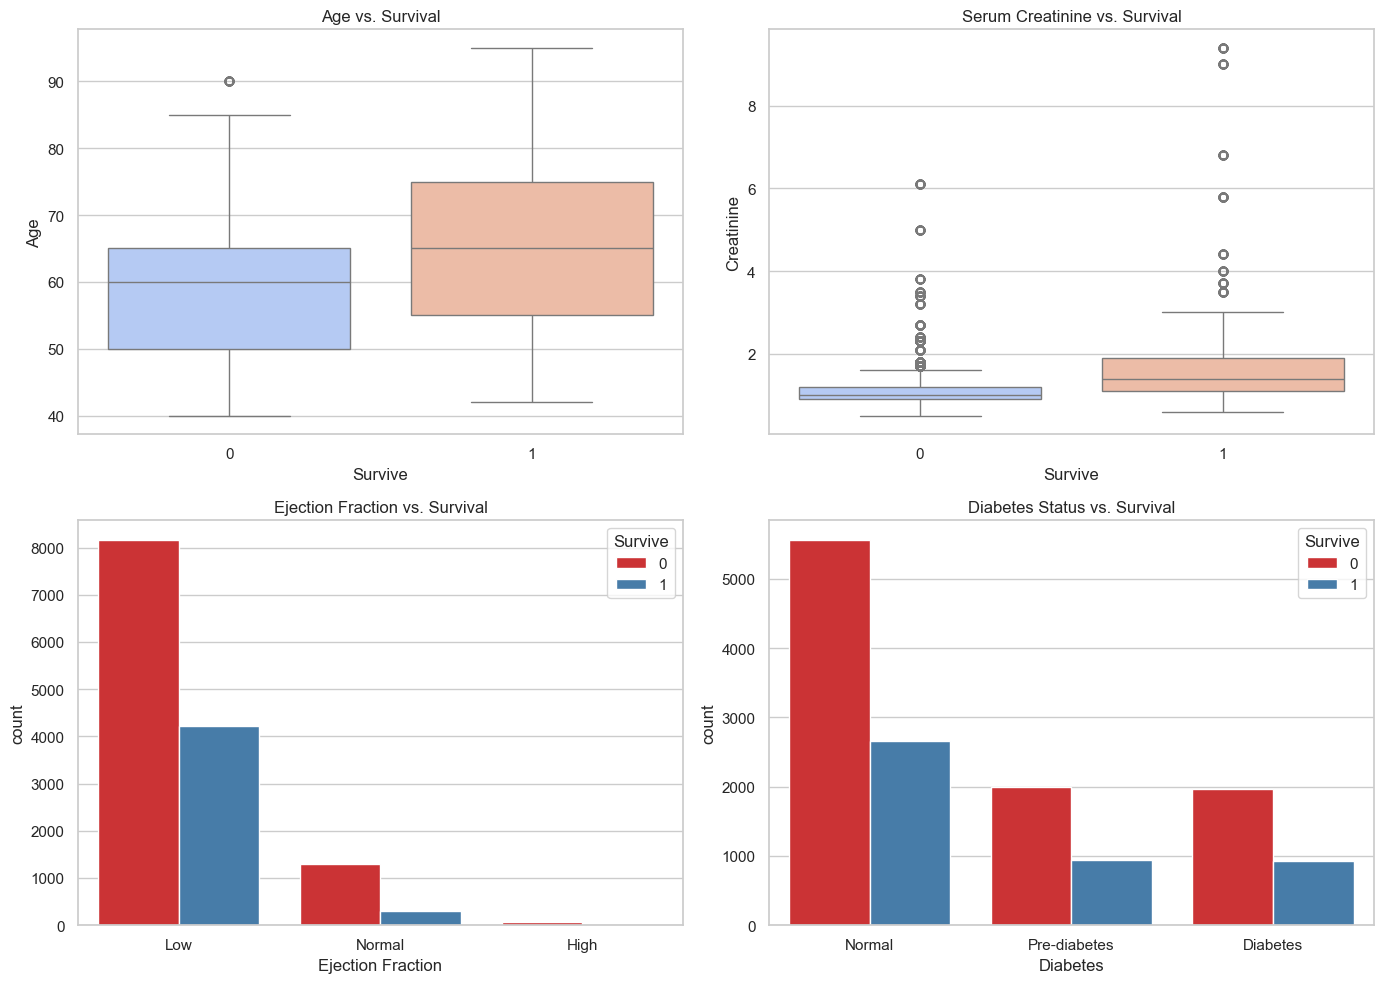

In [47]:
def plot_bivariate_summary(data: pd.DataFrame) -> None:
    """Plot key clinical biomarkers against patient survival."""
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 10))
    sns.boxplot(data=data, x="Survive", y="Age", hue="Survive", ax=ax1, palette="coolwarm", legend=False)
    ax1.set_title("Age vs. Survival")

    sns.boxplot(data=data, x="Survive", y="Creatinine", hue="Survive", ax=ax2, palette="coolwarm", legend=False)
    ax2.set_title("Serum Creatinine vs. Survival")

    sns.countplot(data=data, x="Ejection Fraction", hue="Survive", ax=ax3, palette="Set1",
                  order=["Low", "Normal", "High"])
    ax3.set_title("Ejection Fraction vs. Survival")

    sns.countplot(data=data, x="Diabetes", hue="Survive", ax=ax4, palette="Set1",
                  order=["Normal", "Pre-diabetes", "Diabetes"])
    ax4.set_title("Diabetes Status vs. Survival")
    plt.tight_layout()
    plt.show()

plot_bivariate_summary(df_clean)


## Feature Correlation Matrix & Pairplot Interaction Study

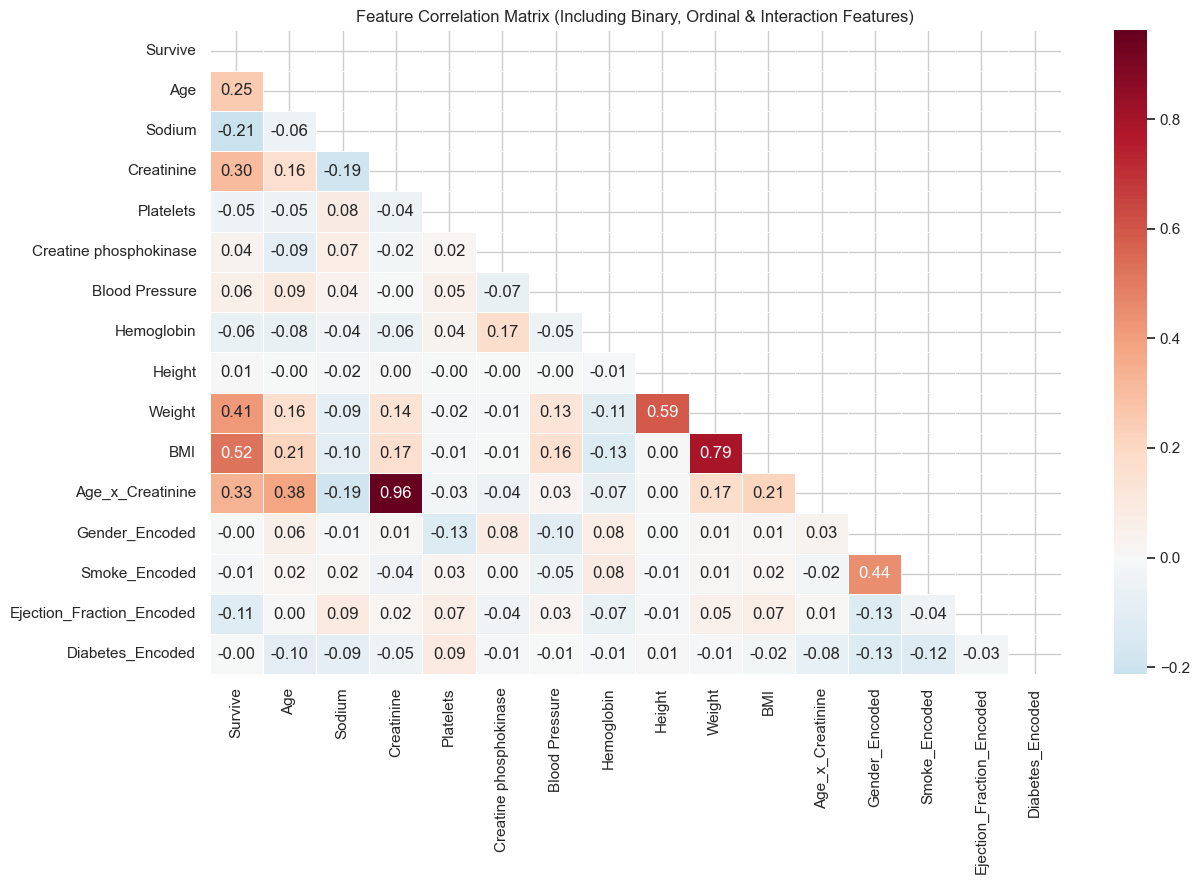

Top Correlations with Survive:


Survive                      1.000000
BMI                          0.521992
Weight                       0.414971
Age_x_Creatinine             0.333829
Creatinine                   0.302269
Age                          0.254982
Blood Pressure               0.060765
Creatine phosphokinase       0.037968
Height                       0.006951
Gender_Encoded              -0.001906
Diabetes_Encoded            -0.003923
Smoke_Encoded               -0.011080
Platelets                   -0.054938
Hemoglobin                  -0.061960
Ejection_Fraction_Encoded   -0.112411
Sodium                      -0.213093
Name: Survive, dtype: float64

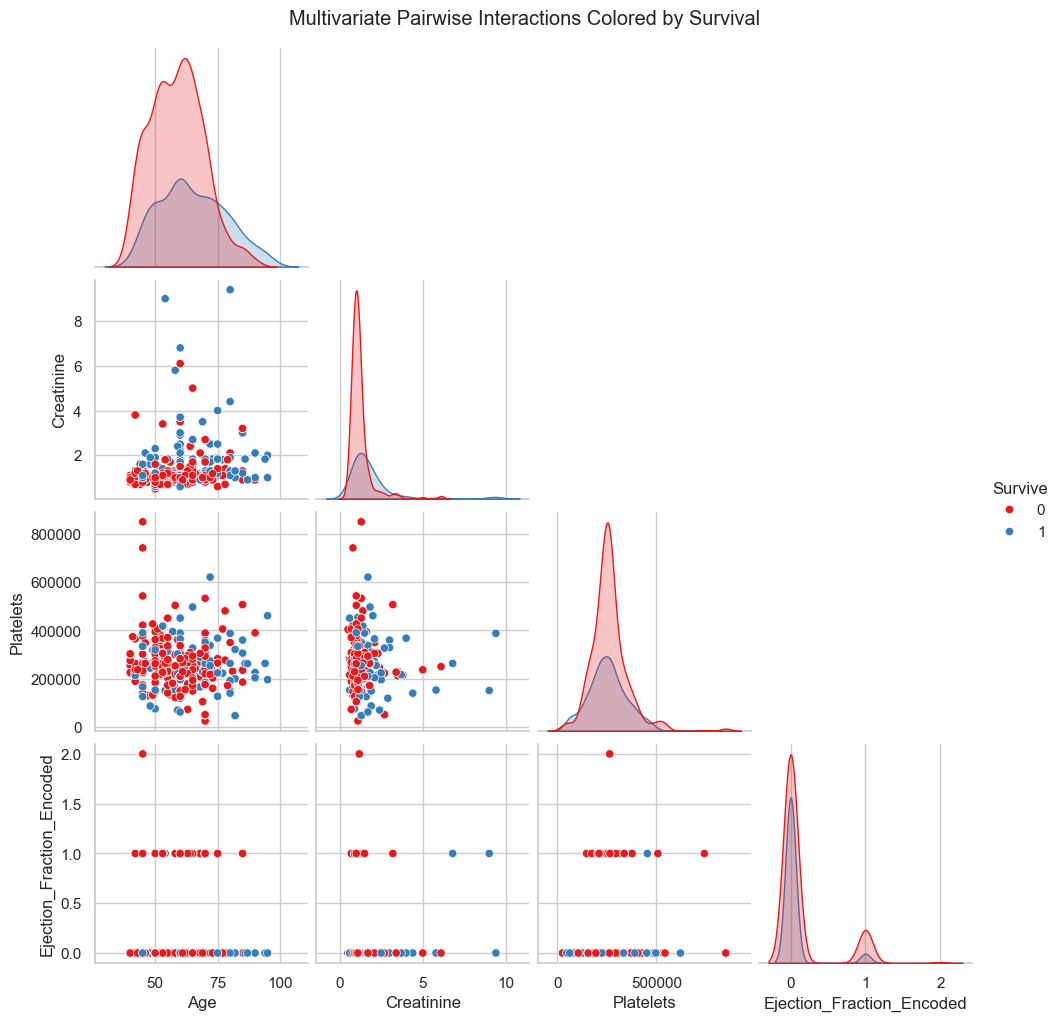

In [48]:
plt.figure(figsize=(13, 9))
corr_matrix = df_encoded.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5)
plt.title("Feature Correlation Matrix (Including Binary, Ordinal & Interaction Features)")
plt.tight_layout()
plt.show()

print("Top Correlations with Survive:")
display(corr_matrix["Survive"].sort_values(ascending=False))

# Focused Pairplot on top clinical drivers
pair_cols = ["Age", "Creatinine", "Platelets", "Ejection_Fraction_Encoded", "Survive"]
sns.pairplot(df_encoded[pair_cols].dropna().sample(min(1000, len(df_encoded)), random_state=42),
             hue="Survive", palette="Set1", corner=True)
plt.suptitle("Multivariate Pairwise Interactions Colored by Survival", y=1.02)
plt.show()


## Multicollinearity Check (VIF)

In [49]:
vif_df = df_encoded.drop(columns=["Survive"]).apply(pd.to_numeric, errors="coerce")
vif_df = vif_df.replace([np.inf, -np.inf], np.nan).dropna(axis=1, how="all")
vif_df = vif_df.fillna(vif_df.median()).fillna(0.0).astype(float)

vif_data = pd.DataFrame({
    "Feature": vif_df.columns,
    "VIF": [variance_inflation_factor(vif_df.values, i) for i in range(len(vif_df.columns))]
}).sort_values(by="VIF", ascending=False)
display(vif_data)


,Feature,VIF
7,Height,580.157259
1,Sodium,556.151043
8,Weight,165.273135
9,BMI,161.924714
2,Creatinine,95.121123
10,Age_x_Creatinine,94.903362
0,Age,77.540933
6,Hemoglobin,28.762271
3,Platelets,8.931225
5,Blood Pressure,8.235405


## Model-Based Feature Importance Ranking (Random Forest)

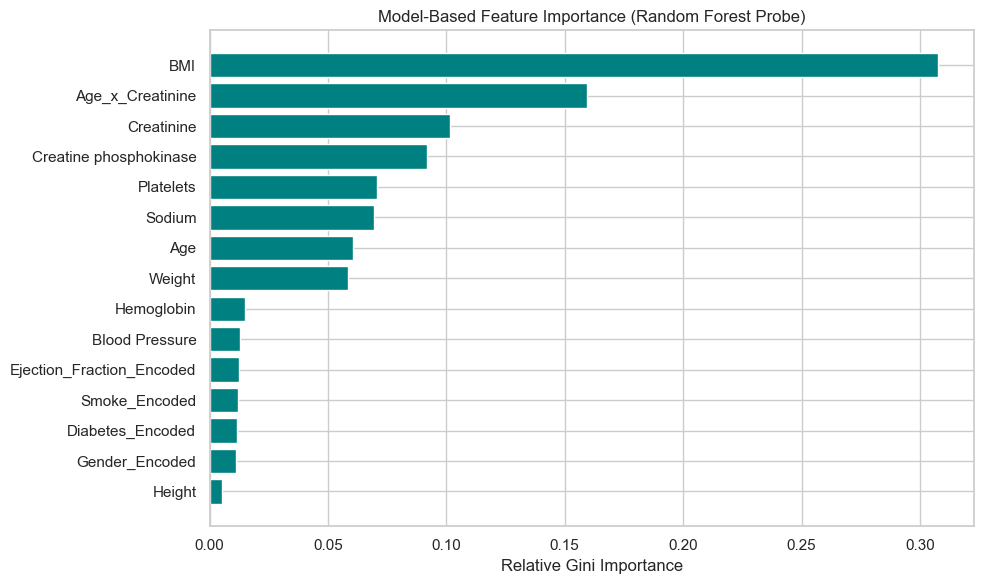

,Feature,Importance
9,BMI,0.307465
10,Age_x_Creatinine,0.159338
2,Creatinine,0.101508
4,Creatine phosphokinase,0.091801
3,Platelets,0.070735
1,Sodium,0.069383
0,Age,0.060578
8,Weight,0.058478
6,Hemoglobin,0.015128
5,Blood Pressure,0.012672


In [50]:
rf_eda_df = df_encoded.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
X_eda = rf_eda_df.drop(columns=["Survive"]).dropna(axis=1, how="all")
X_eda = X_eda.fillna(X_eda.median()).fillna(0.0).astype(float)
y_eda = rf_eda_df["Survive"].astype(int)

rf_probe = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced", n_jobs=-1)
rf_probe.fit(X_eda, y_eda)

importance_df = pd.DataFrame({
    "Feature": X_eda.columns,
    "Importance": rf_probe.feature_importances_
}).sort_values(by="Importance", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(importance_df["Feature"], importance_df["Importance"], color="teal")
plt.title("Model-Based Feature Importance (Random Forest Probe)")
plt.xlabel("Relative Gini Importance")
plt.tight_layout()
plt.show()

display(importance_df.sort_values(by="Importance", ascending=False))
